In [3]:
import trident

2026-04-23 12:35:16,909 | INFO : names.dmp and nodes.dmp exist in /shares/swabseq/trident_globals, skipping download.


2026-04-23 13:16:54,903 | INFO : Taxonomic reestimation data loading complete.
2026-04-23 13:16:55,060 | INFO : Loaded model 0139101_B3_25101602796_S18_R1_001-20260423-120804.
2026-04-23 13:16:55,145 | INFO : Overwriting existing trident model with run_id 0139101_B3_25101602796_S18_R1_001-20260423-120804.
2026-04-23 13:16:59,461 | INFO : Added: `.var["pi"]`, `.var["phi"]`; cached posterior gamma on the model
2026-04-23 13:16:59,615 | INFO : Loaded model 0139101_B3_25101602796_S18_R1_001-20260423-120804.
2026-04-23 13:16:59,994 | INFO : Added: `.var["taxid_cluster"]` and `.var["taxid_cluster_color"]`


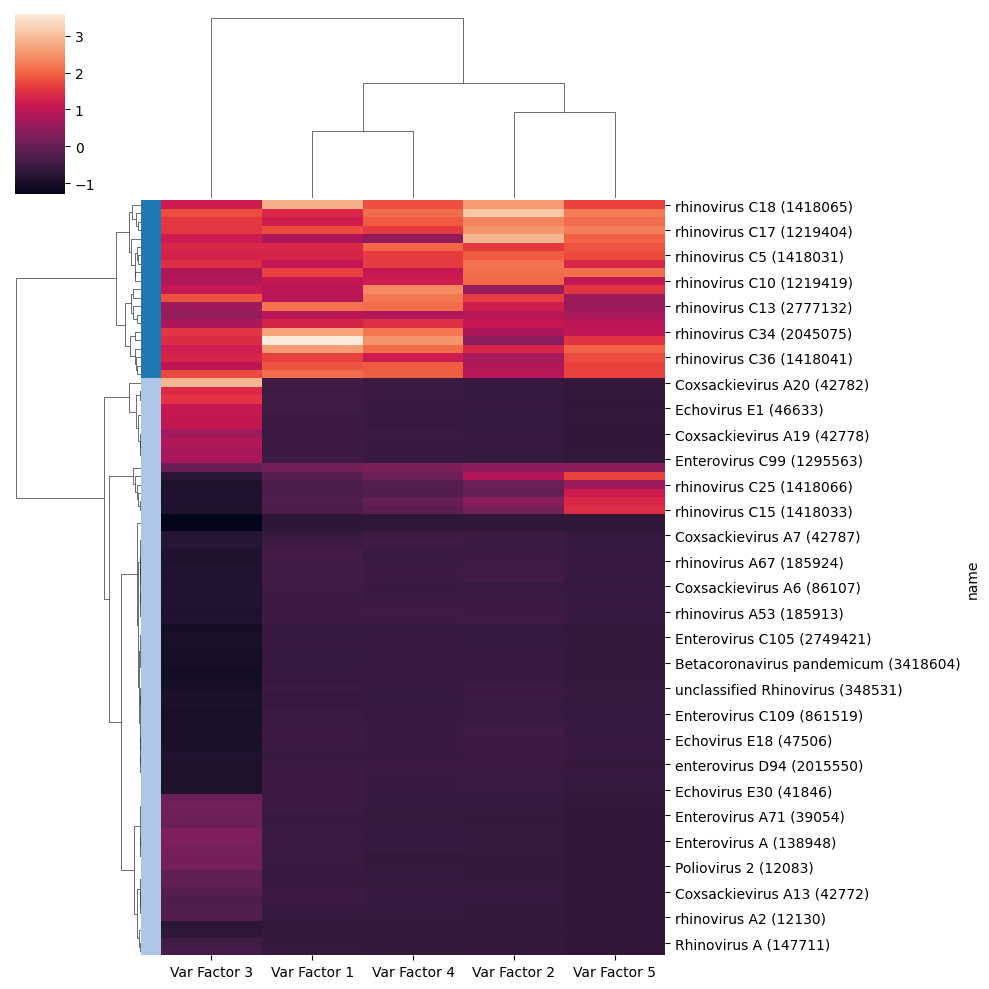

2026-04-23 13:17:02,170 | INFO : Added: `.var[taxid_cluster_lca]`
2026-04-23 13:17:02,311 | INFO : Added `marginal_proba` to .var


In [14]:
config_accs = trident.tl.TridentConfig(
    reads="/shares/swabseq/oregon2/0139101_B3_25101602796_S18_R1_001.fastq.gz",
    pair="/shares/swabseq/oregon2/0139101_B3_25101602796_S18_R1_001.fastq.gz",
    library="/shares/swabseq/db/databases/metagenomic_data/NT_Viral_Data/AllNucleotide_090125_2697049_filtered+2903_rep_COVID_fixed_COVID_naming.fa",
    database="/shares/swabseq/db/databases/metagenomic_data/01Dec2025-AIMetadata-Step3",
    threads=30
)
config_accs.n_steps = 2000
taxonomic_data = trident.tl.taxutils(config_accs)
adata = trident.tl.load_adata(config=config_accs, taxonomic_data=taxonomic_data, rebuild=False)
trident.tl.get_posteriors(adata, num_samples=1000)
trident.pl.var_cluster(
    adata,
    method="ward",
    standardize="zscore_cols",
    mode="silhouette",
)
trident.tl.cluster_lca(adata, taxonomic_data)
trident.tl.var_marginal(adata)
acc_adata = trident.tl.load_accession_adata(config=config_accs, taxonomic_data=taxonomic_data, adata=adata)

In [15]:
adata.uns

{'trident': {'L_file': '/shares/swabseq/trident_globals/0139101_B3_25101602796_S18_R1_001/AllNucleotide_090125_2697049_filtered+2903_rep_COVID_fixed_COVID_naming.coverage.tsv',
  'X_file': '/shares/swabseq/trident_globals/0139101_B3_25101602796_S18_R1_001/0139101_B3_25101602796_S18_R1_001.01Dec2025-AIMetadata-Step3.paired.kraken',
  'basename': '0139101_B3_25101602796_S18_R1_001',
  'config': {'reads': '/shares/swabseq/oregon2/0139101_B3_25101602796_S18_R1_001.fastq.gz',
   'library': '/shares/swabseq/db/databases/metagenomic_data/NT_Viral_Data/AllNucleotide_090125_2697049_filtered+2903_rep_COVID_fixed_COVID_naming.fa',
   'database': '/shares/swabseq/db/databases/metagenomic_data/01Dec2025-AIMetadata-Step3',
   'pair': '/shares/swabseq/oregon2/0139101_B3_25101602796_S18_R2_001.fastq.gz',
   'k': 35,
   'l': 31,
   'spaces': 3,
   'num_reads': 257174,
   'num_targets': 89,
   'num_latent': 5,
   'max_var': 300,
   'max_acc_per_mm': 512,
   'subsample_size': 4096,
   'taxid_filter_quant

In [6]:
acc_adata

AnnData object with n_obs × n_vars = 15765 × 60
    obs: 'read_id', 'kraken_label', 'accession_reestimation', 'accession_proba', 'reestimation', 'read_cluster', 'read_cluster_color'
    var: 'accession', 'seq_len', 'L', 'taxid', 'name', 'sum_r(X_r,t)', 'composite_score', 'phi', 'pi', 'accession_cluster', 'accession_cluster_color', 'accession_cluster_lca', 'marginal_proba'
    uns: 'trident'
    layers: 'probas'

In [15]:
import sys
sys.path.append("../")
import trident
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


2026-04-23 21:10:08,097 | INFO : Added: `.obs["read_cluster"]` and `.obs["read_cluster_color"]`


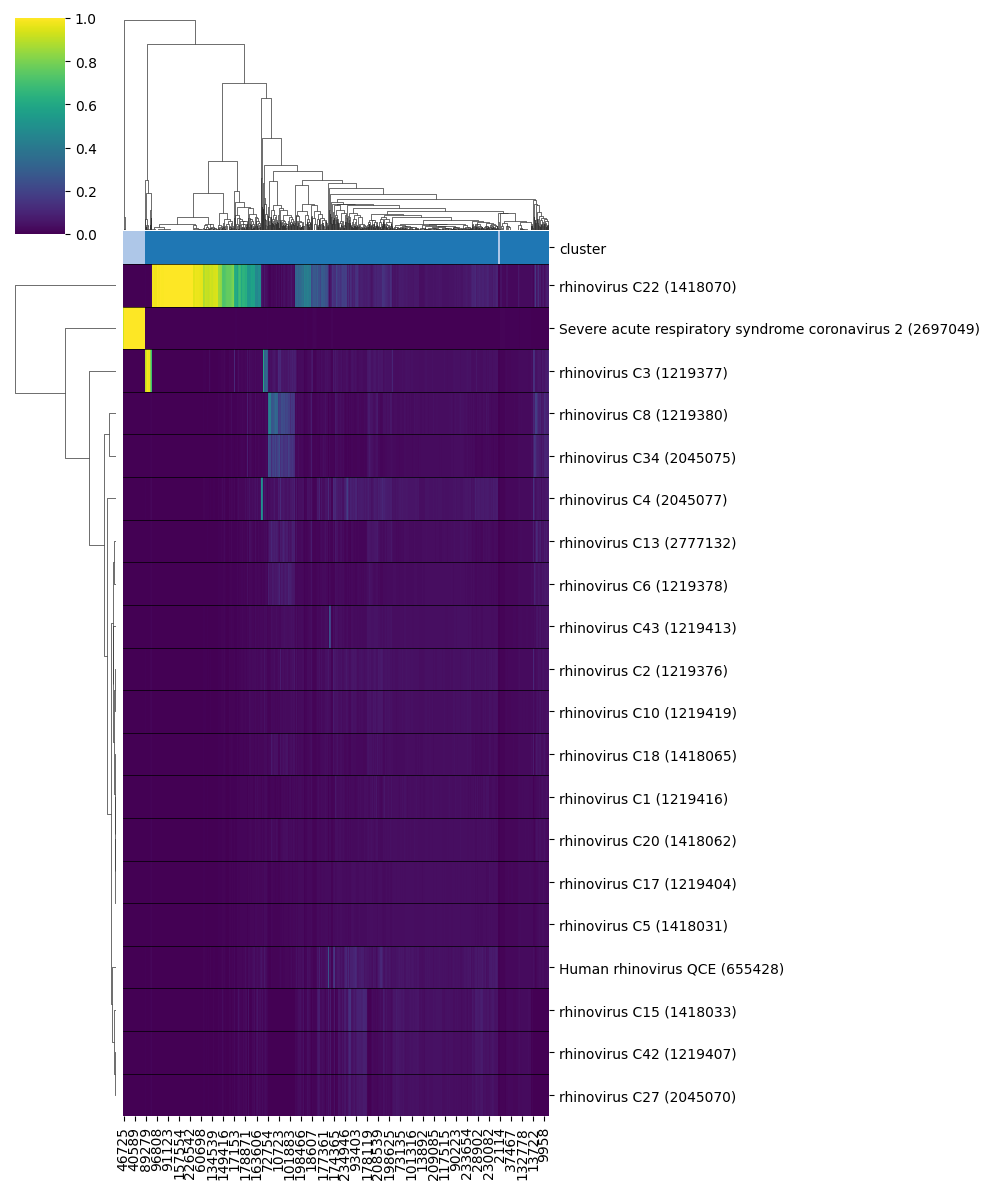

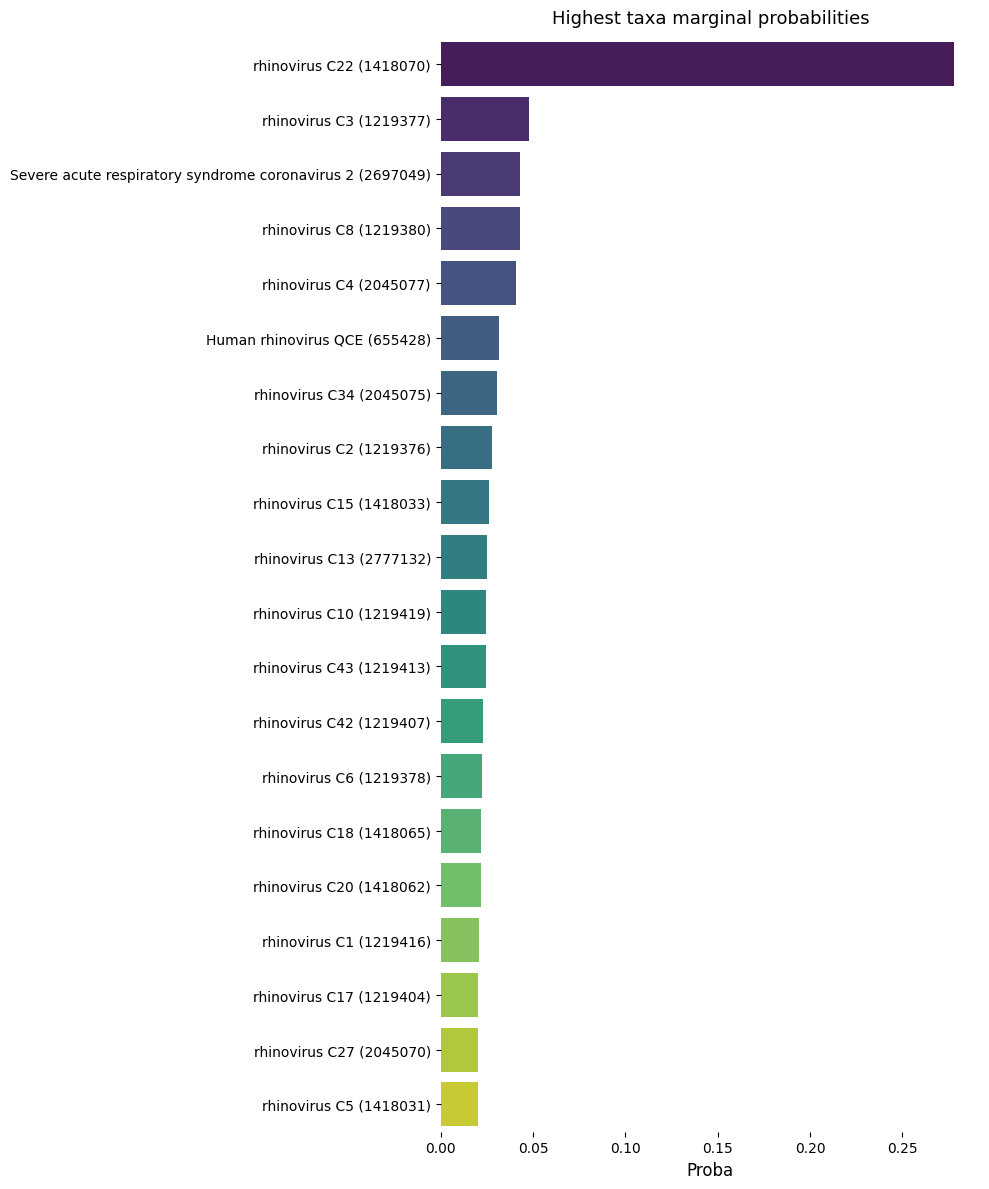

FileNotFoundError: [Errno 2] No such file or directory: '/shares/swabseq/trident_globals/0139101_B3_25101602796_S18_R1_001/0139101_B3_25101602796_S18_R1_001-20260423-120804/trident_model.pt'

In [17]:
import os

def plot_all_diagnostics(adata, acc_adata, save_dir="figures", prefix=""):
    os.makedirs(save_dir, exist_ok=True)
    p = lambda name: os.path.join(save_dir, f"{prefix}{name}.png")

    trident.pl.read_cluster(adata, n_reads_subsample=1000, top_n_var=20, save_path=p("taxa_read_cluster"))
    trident.pl.var_proba(adata, figsize=(10, 12), top_n=20, save_path=p("taxa_var_proba"))
    trident.tl.pi_var(adata, logit=True)
    trident.pl.pi_discordance(adata, top_n=20, save_path=p("taxa_pi_discordance"))

    trident.pl.read_cluster(acc_adata, n_reads_subsample=1000, top_n_var=20, save_path=p("acc_read_cluster"))
    trident.pl.var_proba(acc_adata, figsize=(10, 12), top_n=20, save_path=p("acc_var_proba"))
    trident.tl.pi_var(acc_adata, logit=True)
    trident.pl.pi_discordance(acc_adata, top_n=20, save_path=p("acc_pi_discordance"))
plot_all_diagnostics(adata, acc_adata, save_dir="figures/", prefix="oregon2_B3_")

2026-04-02 18:37:24,239 | INFO : Loaded model 0131403_H02_1_H3N2_D1_S16_R1_001.accessions-20260402-183123.


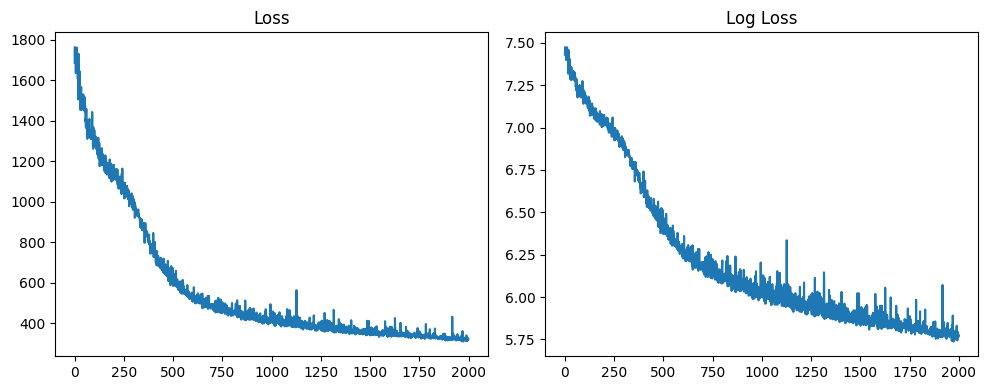

In [118]:
# trident.tl.train_trident(acc_adata, config_accs)
model = trident.tl.load_model(acc_adata)
trident.tl.plot_loss(model.losses)

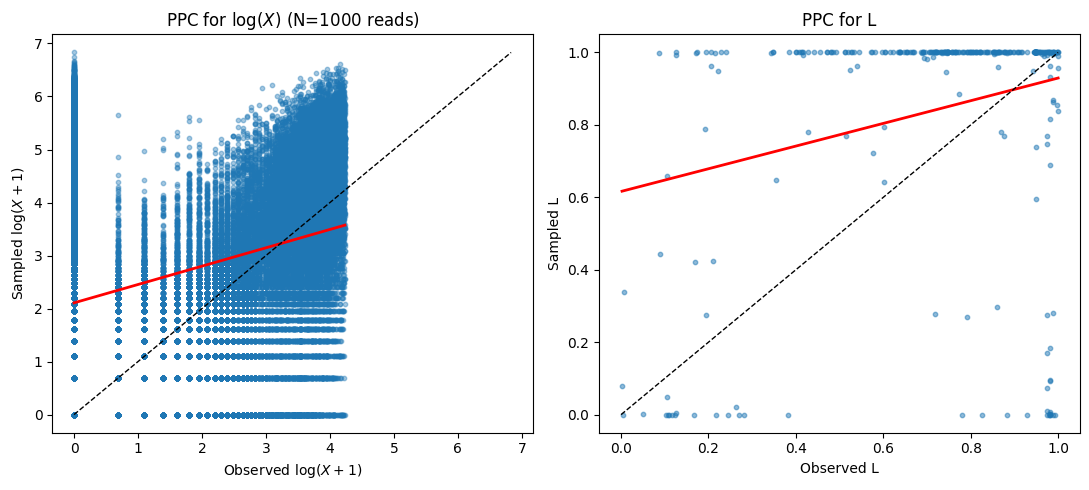

In [96]:
trident.pl.plot_ppc(acc_adata, N=1000)

In [175]:
taxonomic_data.load_a2t(list(acc_adata.var.accession.values))
acc_adata.var["taxid"] = acc_adata.var["accession"].map(taxonomic_data.a2t).fillna(-1)
acc_adata.var["name"] = acc_adata.var["accession"] + " ("+ acc_adata.var["taxid"].map(taxonomic_data.names) + ")"

2026-04-02 20:29:58,204 | INFO : /shares/swabseq/trident_globals/nucl_gb.accession2taxid.gz already exists, skipping download.


In [176]:
trident.tl.get_posteriors(acc_adata, num_samples=1000)

2026-04-02 20:30:02,281 | INFO : Loaded model 0131403_H02_1_H3N2_D1_S16_R1_001.accessions-20260402-183123.
2026-04-02 20:30:02,330 | INFO : Overwriting existing trident model with run_id 0131403_H02_1_H3N2_D1_S16_R1_001.accessions-20260402-183123.
... storing 'accession_reestimation' as categorical
2026-04-02 20:30:04,775 | INFO : Added: `.var["pi"]`, `.var["phi"]`; cached posterior gamma on the model


2026-04-02 20:30:05,352 | INFO : Loaded model 0131403_H02_1_H3N2_D1_S16_R1_001.accessions-20260402-183123.
2026-04-02 20:30:05,853 | INFO : Added: `.var["accession_cluster"]` and `.var["accession_cluster_color"]`


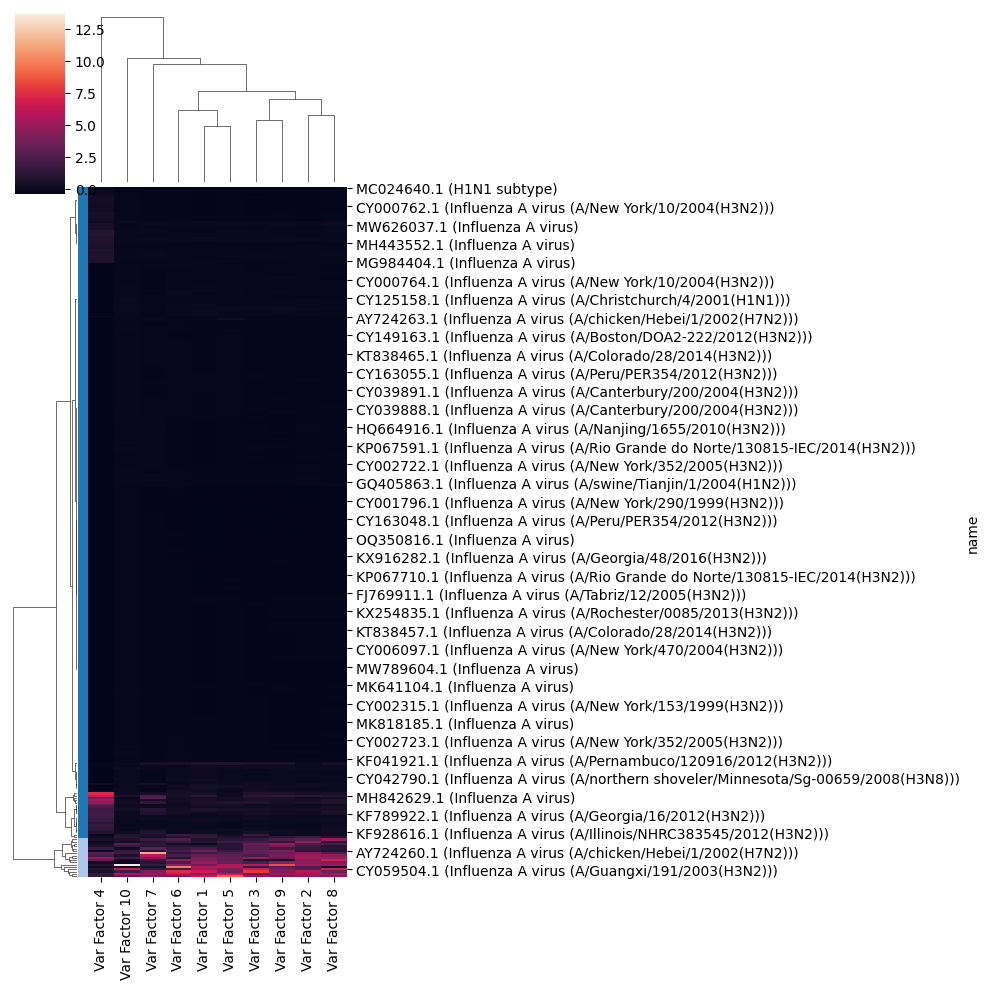

2026-04-02 20:30:07,782 | INFO : Added: `.var[accession_cluster_lca]`
2026-04-02 20:30:08,456 | INFO : Loaded model 0131403_H02_1_H3N2_D1_S16_R1_001.accessions-20260402-183123.


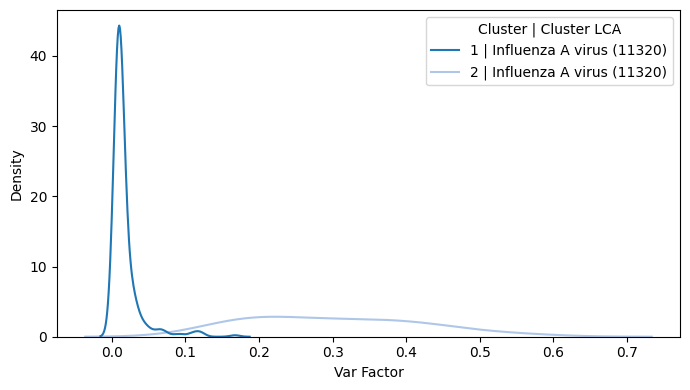

In [177]:
trident.pl.var_cluster(
    acc_adata, 
    method="ward", 
    standardize="zscore_cols", 
    mode="silhouette"
)
trident.tl.cluster_lca(acc_adata, taxonomic_data)
trident.pl.var_factor_density(acc_adata, taxonomic_data)

2026-04-02 23:52:38,082 | INFO : Added: `.obs["read_cluster"]` and `.obs["read_cluster_color"]`


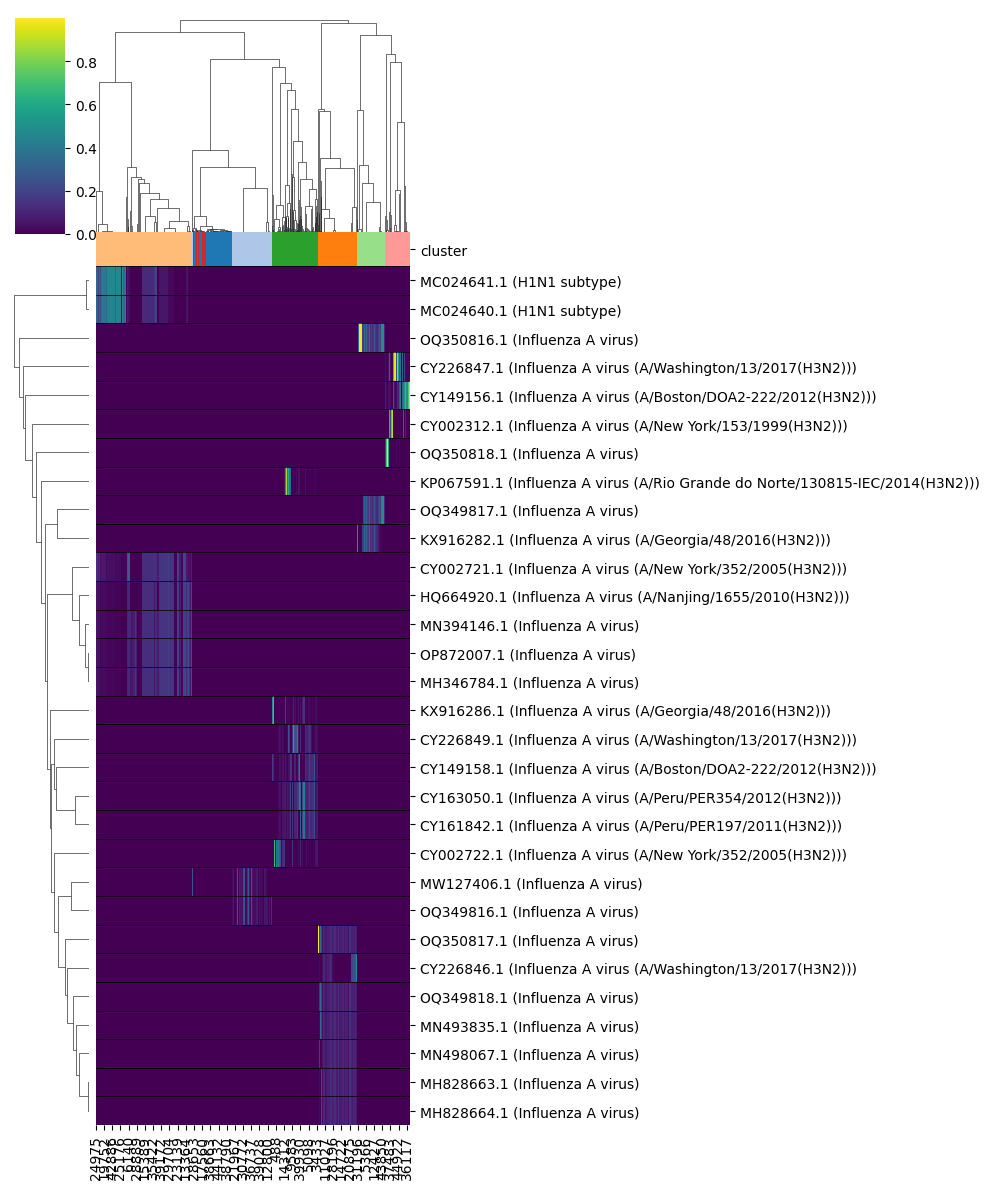

In [192]:
# trident.tl._get_read_probabilities(acc_adata)
# trident.tl.reestimate(acc_adata, taxonomic_data)
# trident.tl.var_marginal(acc_adata)
trident.pl.read_cluster(acc_adata, n_reads_subsample=1000, top_n_var=30)

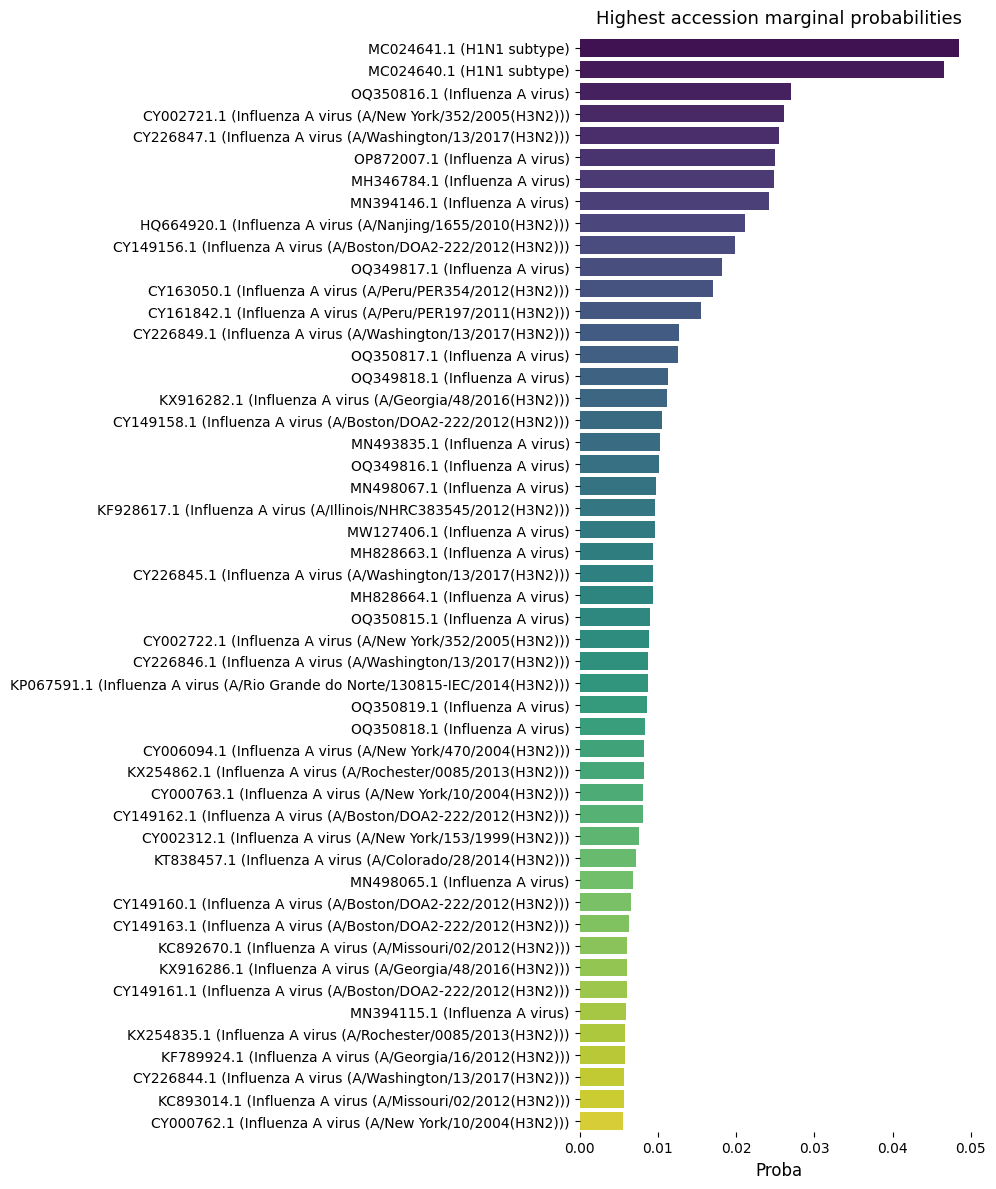

In [180]:
trident.pl.var_proba(acc_adata, figsize=(10, 12), top_n=50)

In [181]:
acc_adata.var.sort_values("marginal_proba")

,accession,seq_len,L,taxid,name,"sum_r(X_r,t)",composite_score,phi,pi,accession_cluster,accession_cluster_color,accession_cluster_lca,marginal_proba,pi_var,pi_q50
540,AB911602.1,1565,0.117083,1468134,AB911602.1 (Influenza A virus (A/swine/Hiroshi...,8804,0.357373,0.884485,0.003295,2,#aec7e8,11320,0.000119,7.401817e-07,0.003220
1499,CY042789.1,1903,0.110585,657846,CY042789.1 (Influenza A virus (A/northern shov...,13928,0.454424,0.865223,0.004471,2,#aec7e8,11320,0.000119,9.774831e-07,0.004371
538,AB911600.1,2233,0.103495,1468134,AB911600.1 (Influenza A virus (A/swine/Hiroshi...,10214,0.373727,0.825943,0.007221,2,#aec7e8,11320,0.000120,5.318675e-06,0.007027
1850,AJ867074.1,1707,0.003630,303316,AJ867074.1 (Influenza A virus (A/Hatay/2004/(H...,6,0.065416,0.706872,0.054066,1,#1f77b4,11320,0.000120,1.194621e-03,0.047589
1092,CY125158.1,1433,0.002203,1194324,CY125158.1 (Influenza A virus (A/Christchurch/...,5,0.058981,0.703813,0.087283,1,#1f77b4,11320,0.000120,3.045111e-03,0.074484
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
440,CY226847.1,1737,0.875666,1979035,CY226847.1 (Influenza A virus (A/Washington/13...,90733,0.871314,0.697174,0.985172,1,#1f77b4,11320,0.025526,2.531927e-05,0.986084
1814,CY002721.1,1026,0.774096,335301,CY002721.1 (Influenza A virus (A/New York/352/...,113866,0.873727,0.702132,0.944190,1,#1f77b4,11320,0.026155,2.529396e-04,0.945379
48,OQ350816.1,2274,0.997326,11320,OQ350816.1 (Influenza A virus),120914,0.986327,0.697032,0.987266,1,#1f77b4,11320,0.027036,1.867805e-05,0.988204
74,MC024640.1,1027,0.400000,114727,MC024640.1 (H1N1 subtype),78285,0.786327,0.699706,0.956842,1,#1f77b4,11320,0.046550,1.059933e-04,0.957752


2026-04-02 20:30:25,231 | INFO : Loaded model 0131403_H02_1_H3N2_D1_S16_R1_001.accessions-20260402-183123.
2026-04-02 20:30:25,746 | INFO : Loaded model 0131403_H02_1_H3N2_D1_S16_R1_001.accessions-20260402-183123.


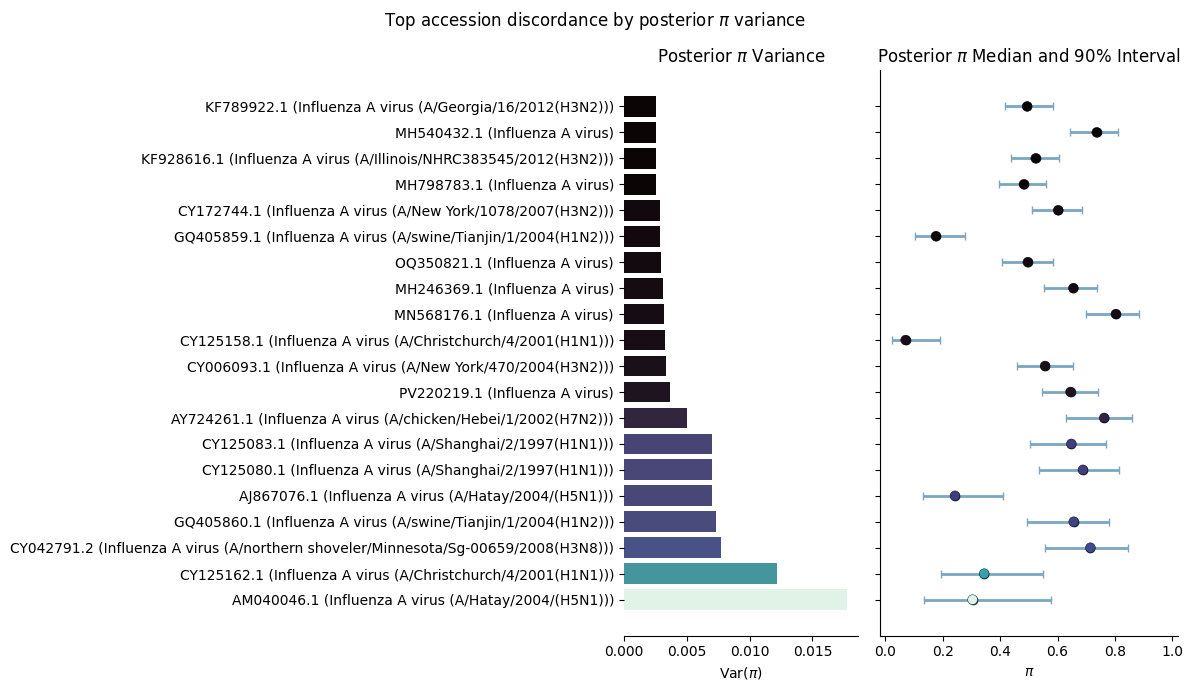

In [182]:
trident.tl.pi_var(acc_adata,logit=True)
trident.pl.pi_discordance(acc_adata, top_n=20)

In [165]:
acc_adata.var["name"].astype(str)

0                                  Influenza A virus
1                                  Influenza A virus
2                                  Influenza A virus
3                                  Influenza A virus
4                                  Influenza A virus
                            ...                     
1845    Influenza A virus (A/New York/10/2004(H3N2))
1846    Influenza A virus (A/New York/10/2004(H3N2))
1849         Influenza A virus (A/Hatay/2004/(H5N1))
1850         Influenza A virus (A/Hatay/2004/(H5N1))
1859      Influenza A virus (A/Bangkok/1/1979(H3N2))
Name: name, Length: 300, dtype: object

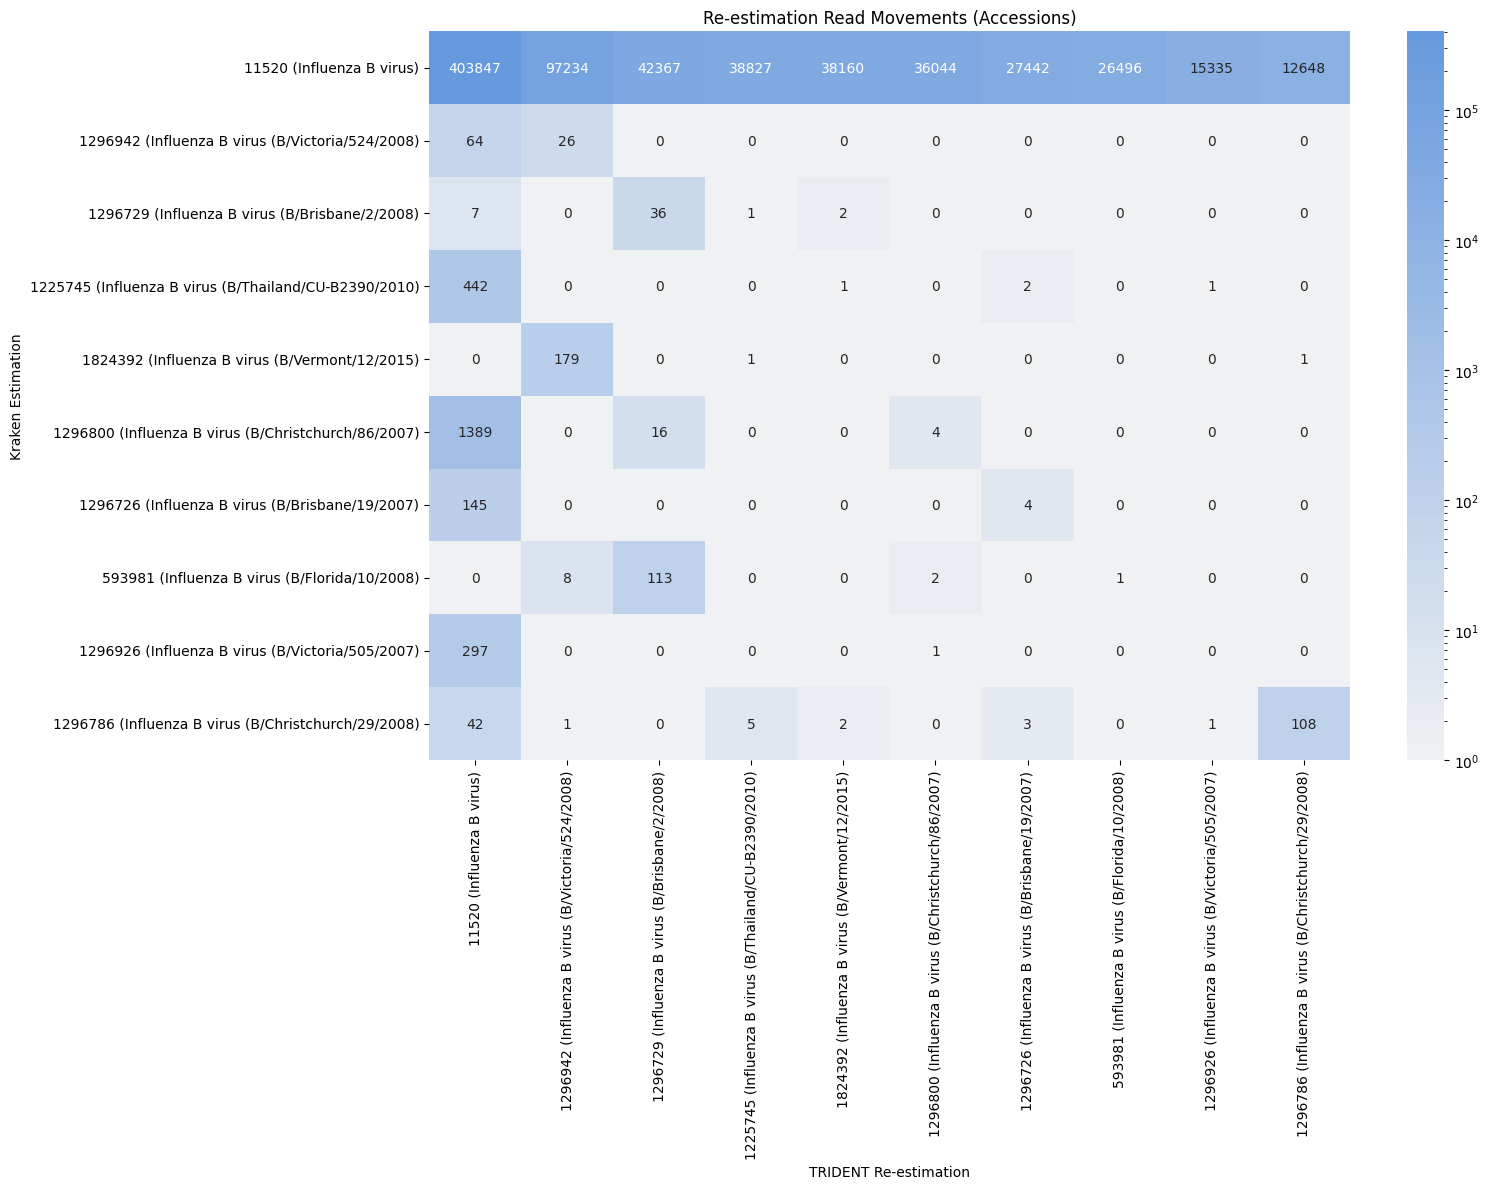

In [225]:
trident.pl.transition(acc_adata, quantile=.995, figsize=(16, 12), save_path="trans_mtx_H10_tecan_lod.png")
# treport = trident.tl.to_treport(acc_adata, taxonomic_data)
# trident.pl.taxid_totals(acc_adata, taxonomic_data, quantile=.99)

In [64]:
acc_adata.obs

,read_id,kraken_label,accession_reestimation,accession_proba,reestimation,read_cluster_color,read_cluster
0,VH00763:86:AAHHTNKM5:1:1101:54417:1246,11320.0,MH346784.1,0.084566,11320.0,#ffbb78,4
1,VH00763:86:AAHHTNKM5:1:1101:44305:1625,11320.0,MH346784.1,0.020463,11320.0,#2ca02c,5
2,VH00763:86:AAHHTNKM5:1:1101:27775:1757,11320.0,CY163050.1,0.086311,1425999.0,#2ca02c,5
3,VH00763:86:AAHHTNKM5:1:1101:35084:1757,11320.0,CY092085.1,0.065208,1043150.0,#ff7f0e,3
4,VH00763:86:AAHHTNKM5:1:1101:35917:1757,11320.0,CY000762.1,0.199419,311588.0,#ffbb78,4
...,...,...,...,...,...,...,...
45949,VH00763:86:AAHHTNKM5:1:2611:66971:54956,11320.0,MH346784.1,0.188398,11320.0,#ffbb78,4
45950,VH00763:86:AAHHTNKM5:1:2611:64339:55353,11320.0,MH346784.1,0.089040,11320.0,#ffbb78,4
45951,VH00763:86:AAHHTNKM5:1:2611:43775:55618,11320.0,CY149160.1,0.166593,1396918.0,#d62728,7
45952,VH00763:86:AAHHTNKM5:1:2611:63298:55978,11320.0,CY161847.1,0.178395,1427910.0,#aec7e8,2


In [30]:
acc_adata.var.sort_values("L").tail(40)

,accession,seq_len,L,taxid,name,"sum_r(X_r,t)",composite_score,phi,pi,accession_cluster,accession_cluster_color,accession_cluster_lca,marginal_proba,pi_var,pi_q50
535,CY189883.1,982,0.882911,1636776,CY189883.1 (Influenza A virus (A/Oklahoma/3963...,5684,0.553887,0.773642,0.234681,2,#aec7e8,11320,0.000220,0.001632,0.232194
489,KX254862.1,2277,0.883534,1652978,KX254862.1 (Influenza A virus (A/Rochester/008...,107896,0.895040,0.697121,0.977535,2,#aec7e8,11320,0.009909,0.000059,0.979170
522,KT838529.1,2274,0.883534,1731058,KT838529.1 (Influenza A virus (A/Colorado/28/2...,107383,0.894504,0.697130,0.979607,2,#aec7e8,11320,0.010690,0.000048,0.980840
1110,CY092085.1,1464,0.887734,1043150,CY092085.1 (Influenza A virus (A/Taiwan/426/20...,94364,0.879893,0.697123,0.977215,2,#aec7e8,11320,0.008241,0.000075,0.978211
723,CY172746.1,1534,0.890411,1468730,CY172746.1 (Influenza A virus (A/New York/1078...,93869,0.879357,0.697543,0.973267,2,#aec7e8,11320,0.004384,0.000067,0.974877
486,KX254834.1,2286,0.890789,1652978,KX254834.1 (Influenza A virus (A/Rochester/008...,129266,0.905094,0.700097,0.972981,2,#aec7e8,11320,0.003534,0.000075,0.974157
515,KT838457.1,2151,0.897436,1731058,KT838457.1 (Influenza A virus (A/Colorado/28/2...,133691,0.907507,0.699141,0.973825,2,#aec7e8,11320,0.006543,0.000094,0.976396
521,KT838527.1,1497,0.897590,1731058,KT838527.1 (Influenza A virus (A/Colorado/28/2...,93417,0.879088,0.697181,0.977421,2,#aec7e8,11320,0.005109,0.000087,0.978327
768,CY149163.1,2310,0.900000,1396918,CY149163.1 (Influenza A virus (A/Boston/DOA2-2...,133514,0.907909,0.699194,0.977870,2,#aec7e8,11320,0.010883,0.000056,0.978706
749,CY163049.1,999,0.900000,1425999,CY163049.1 (Influenza A virus (A/Peru/PER354/2...,16221,0.770107,0.720276,0.763378,2,#aec7e8,11320,0.001065,0.001962,0.767170


In [32]:
acc_adata.var.sort_values("L")

,accession,seq_len,L,taxid,name,"sum_r(X_r,t)",composite_score,phi,pi,accession_cluster,accession_cluster_color,accession_cluster_lca,marginal_proba,pi_var,pi_q50
6864,DI250803.1,982,0.415663,114727,DI250803.1 (H1N1 subtype),29,0.072250,0.698360,0.002439,2,#aec7e8,114727,0.000065,4.271440e-07,0.002058
6862,DI250791.1,982,0.415663,114727,DI250791.1 (H1N1 subtype),29,0.072250,0.693150,0.061710,1,#1f77b4,2955291,0.000063,2.402683e-03,0.066983
6861,DI250785.1,982,0.416918,114727,DI250785.1 (H1N1 subtype),29,0.074925,0.693166,0.013332,1,#1f77b4,2955291,0.000063,2.211509e-05,0.010586
6863,DI250797.1,982,0.416918,114727,DI250797.1 (H1N1 subtype),29,0.074925,0.693166,0.007747,1,#1f77b4,2955291,0.000063,1.118677e-05,0.007614
562,MC024639.1,2233,0.428571,114727,MC024639.1 (H1N1 subtype),2091020,0.544475,0.693150,0.768711,1,#1f77b4,2955291,0.000103,2.449004e-03,0.759739
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7,PX708511.1,1540,0.990403,11320,PX708511.1 (Influenza A virus),1642758,0.986275,0.693149,0.916448,1,#1f77b4,2955291,0.000457,6.927396e-04,0.914230
12,PV995787.1,1540,0.990403,11320,PV995787.1 (Influenza A virus),1666611,0.986575,0.693148,0.936329,1,#1f77b4,2955291,0.000846,3.017089e-04,0.942009
22,PQ638256.1,1413,0.991597,11320,PQ638256.1 (Influenza A virus),1540512,0.983850,0.693149,0.923118,1,#1f77b4,2955291,0.000345,5.414028e-04,0.922684
97,OZ031743.1,982,1.000000,2955291,OZ031743.1 (Alphainfluenzavirus influenzae),9411480,0.998025,0.693150,0.969283,1,#1f77b4,2955291,0.075111,8.438902e-05,0.974759


NameError: name 'is_notebook' is not defined

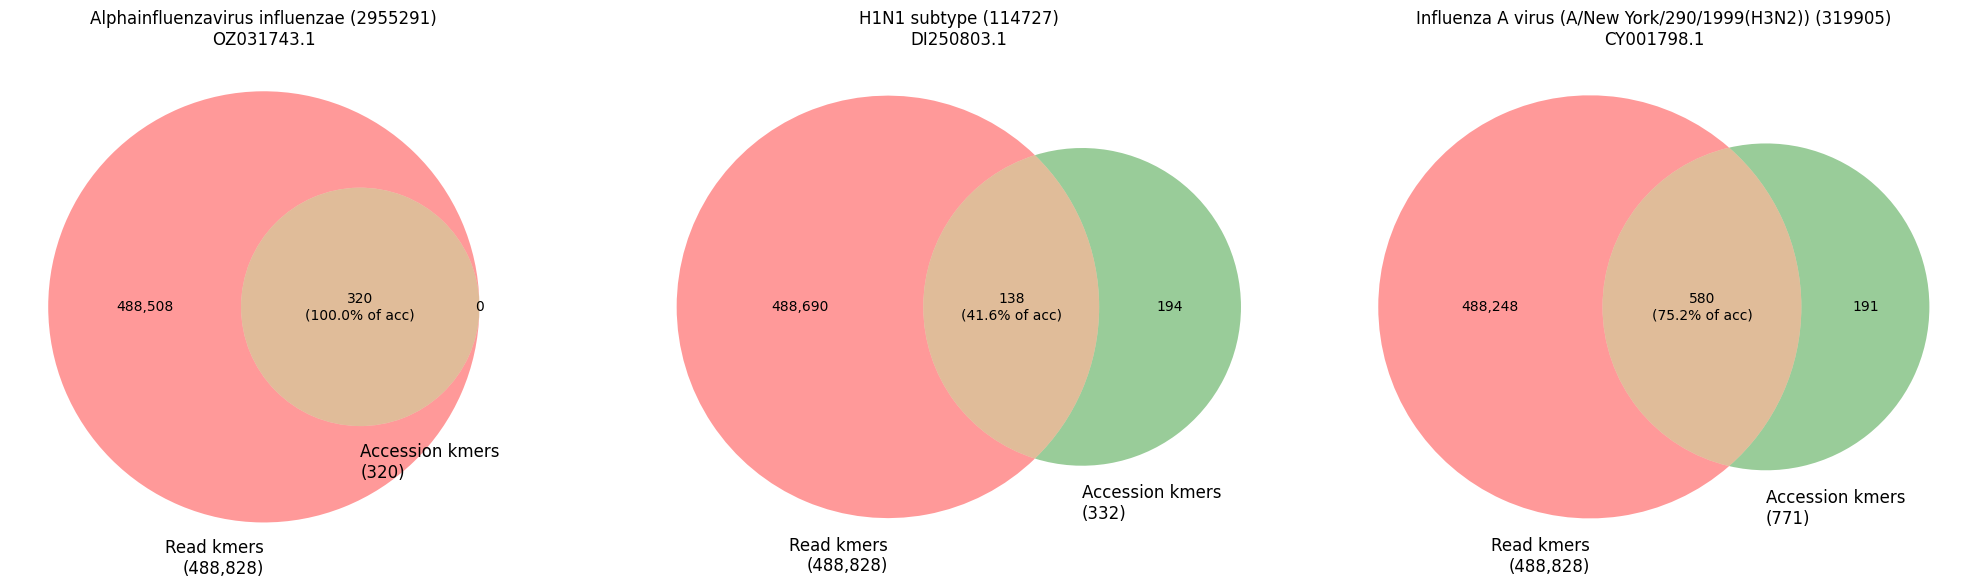

In [34]:
trident.pl.kmer_venn(
    acc_adata,
    taxonomic_data=taxonomic_data,
    accessions=["OZ031743.1", "DI250803.1", "CY001798.1"],
    save_path="figures/accession_venn_diagram.png"
)